In [7]:
from ultralytics import YOLO
from os.path import isfile

DatasetPath = "./datasets/GTSDB/"

In [8]:
if not isfile(DatasetPath+"data.yaml"):
    from ultralytics.data.converter import convert_ndjson_to_yolo
    await convert_ndjson_to_yolo("datasets/GTSDB/GTSDB.ndjson")

FileNotFoundError: 'datasets/GTSDB/GTSDB.ndjson' does not exist

In [9]:
model = YOLO("yolov8n.pt")
results = model.train(data=DatasetPath+"data.yaml", epochs=500, patience=50, imgsz=640, batch=40, fliplr=0.0, flipud=0.0)#000000000, freeze=10
#results = model.train(data=DatasetPath+"data.yaml", epochs=300 batch=16 workers=8 lr0=0.002 momentum=0.9 weight_decay=0.0005 warmup_epochs=3 warmup_momentum=0.8 warmup_bias_lr=0.1 optimizer=AdamW patience=30, fliplr=0.0, flipud=0.0)
#epochs=100 batch=16 workers=8 lr0=0.002 momentum=0.9 weight_decay=0.0005 warmup_epochs=3 warmup_momentum=0.8 warmup_bias_lr=0.1 optimizer=AdamW patience=30

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.211  Python-3.14.7 torch-2.15.0+cu134 CUDA:0 (NVIDIA GeForce GTX 1660 Ti, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=40, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./datasets/GTSDB/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=500, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n

RuntimeError: Dataset 'datasets/GTSDB/data.yaml' error  './datasets/GTSDB/data.yaml' does not exist

In [3]:
export = model.export(format="onnx")
print(export)

Ultralytics 8.4.198  Python-3.14.8 torch-2.15.0+cu134 CPU (Intel Core i9-14900HX)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from 'C:\Users\Caspe\SEM3-Signs\runs\detect\train-25\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success  4.0s, saved as 'C:\Users\Caspe\SEM3-Signs\runs\detect\train-25\weights\best.onnx' (12.2 MB)

Export complete (4.3s)
Results saved to C:\Users\Caspe\SEM3-Signs\runs\detect\train-25\weights\best.onnx
Predict:         yolo predict task=detect model=C:\Users\Caspe\SEM3-Signs\runs\detect\train-25\weights\best.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\Users\Caspe\SEM3-Signs\runs\detect\train-25\weights\best.onnx imgsz=640 data=datasets\GTSDBmod1\data.yaml 
Visualize:       https://netron.app
C:\Users\Caspe\SEM3-Signs\runs\detect\train

In [3]:
bmodel = YOLO("./runs/detect/train-25/weights/best.pt")

In [5]:
files = ["Test.jpg", "Test2.jpg", "test3.png", "test4.png", "test5.png", "test6.png", "test7.png", "test8.png"]
results = bmodel(files)  # return a list of Results objects

# Process results list
for i, result in enumerate(results):
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    obb = result.obb  # Oriented boxes object for OBB outputs
    #result.show()  # display to screen
    result.save(filename=files[i]+"result.jpg")  # save to disk


0: 640x640 (no detections), 3.0ms
1: 640x640 22 Signs, 3.0ms
2: 640x640 26 Signs, 3.0ms
3: 640x640 8 Signs, 3.0ms
4: 640x640 25 Signs, 3.0ms
5: 640x640 12 Signs, 3.0ms
6: 640x640 32 Signs, 3.0ms
7: 640x640 4 Signs, 3.0ms
Speed: 8.9ms preprocess, 3.0ms inference, 3.7ms postprocess per image at shape (1, 3, 640, 640)


In [7]:
results = bmodel.val(data=DatasetPath+"data.yaml", plots=True)

Ultralytics 8.4.198  Python-3.14.8 torch-2.15.0+cu134 CUDA:0 (NVIDIA GeForce RTX 4070 Laptop GPU, 8188MiB)
Model summary (fused): 73 layers, 3,142,913 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 781.0±168.3 MB/s, size: 371.1 KB)
val: Scanning C:\Users\Caspe\SEM3-Signs\datasets\GTSDB\labels\val.cache... 120 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 20.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.4it/s 5.6s0.3s5
                   all        120        194      0.419      0.318      0.369      0.299
                  bend          5          5          0          0          0          0
             bend left          1          1      0.224          1      0.995      0.497
            bend right          2          2          0          0     0.0707     0.0495
          construction          7          7      0.203      0.224      0.241      0.211
 

In [ ]:
import torch
print(torch.cuda.is_available())


0: 640x640 1 Sign, 66.1ms
1: 640x640 1 Sign, 66.1ms
2: 640x640 1 Sign, 66.1ms
3: 640x640 (no detections), 66.1ms
4: 640x640 (no detections), 66.1ms
5: 640x640 2 Signs, 66.1ms
6: 640x640 (no detections), 66.1ms
7: 640x640 1 Sign, 66.1ms
8: 640x640 1 Sign, 66.1ms
9: 640x640 (no detections), 66.1ms
10: 640x640 (no detections), 66.1ms
11: 640x640 2 Signs, 66.1ms
12: 640x640 2 Signs, 66.1ms
13: 640x640 (no detections), 66.1ms
14: 640x640 (no detections), 66.1ms
15: 640x640 (no detections), 66.1ms
16: 640x640 1 Sign, 66.1ms
17: 640x640 1 Sign, 66.1ms
18: 640x640 (no detections), 66.1ms
19: 640x640 (no detections), 66.1ms
20: 640x640 (no detections), 66.1ms
21: 640x640 1 Sign, 66.1ms
22: 640x640 1 Sign, 66.1ms
23: 640x640 1 Sign, 66.1ms
24: 640x640 1 Sign, 66.1ms
25: 640x640 (no detections), 66.1ms
26: 640x640 1 Sign, 66.1ms
27: 640x640 1 Sign, 66.1ms
28: 640x640 (no detections), 66.1ms
29: 640x640 1 Sign, 66.1ms
30: 640x640 1 Sign, 66.1ms
31: 640x640 2 Signs, 66.1ms
32: 640x640 2 Signs, 66.

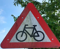

./OURData/padded everything/20260907_185927.jpg


./OURData/padded everything/20260907_190029.jpg


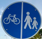

./OURData/padded everything/20260907_190040.jpg
./OURData/padded everything/20260907_190103.jpg
./OURData/padded everything/20260907_190110.jpg


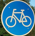

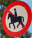

./OURData/padded everything/20260907_190141.jpg
./OURData/padded everything/20260927_211849.jpg


./OURData/padded everything/20260927_211923.jpg


./OURData/padded everything/20260927_211951.jpg
./OURData/padded everything/20260927_212010.jpg
./OURData/padded everything/20260927_212037.jpg


./OURData/padded everything/20260927_212053.jpg


./OURData/padded everything/20260927_212117.jpg
./OURData/padded everything/20260927_212141.jpg
./OURData/padded everything/20260927_212202.jpg
./OURData/padded everything/20260928_185855.jpg


./OURData/padded everything/20260928_185914.jpg


./OURData/padded everything/20260928_185917.jpg
./OURData/padded everything/20260928_185949.jpg
./OURData/padded everything/20260928_185950.jpg
./OURData/padded everything/20260928_190012.jpg


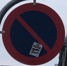

./OURData/padded everything/20260928_190028.jpg


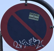

./OURData/padded everything/20260928_210443.jpg


./OURData/padded everything/20260928_210451.jpg


./OURData/padded everything/20260928_210710.jpg
./OURData/padded everything/20260928_210814.jpg


./OURData/padded everything/20260928_210833.jpg


./OURData/padded everything/20260928_210849.jpg
./OURData/padded everything/20260928_210919.jpg


./OURData/padded everything/20260928_211044.jpg


./OURData/padded everything/20260928_211052.jpg


./OURData/padded everything/20260928_211058.jpg


./OURData/padded everything/20260928_211120.jpg


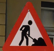

./OURData/padded everything/20260928_211123.jpg


./OURData/padded everything/20260928_214256.jpg
./OURData/padded everything/20260928_214309.jpg
./OURData/padded everything/20260929_114803.jpg


./OURData/padded everything/20260929_124123.jpg


./OURData/padded everything/20260929_124313.jpg


./OURData/padded everything/20260929_164012.jpg
./OURData/padded everything/20260929_164030.jpg


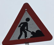

./OURData/padded everything/20261002_144819.jpg


./OURData/padded everything/20261007_091640.jpg


./OURData/padded everything/20261007_091646.jpg


./OURData/padded everything/20261007_092523.jpg


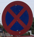

./OURData/padded everything/20261009_142236.jpg


./OURData/padded everything/20261011_110535.jpg
./OURData/padded everything/20261012_115636.jpg


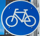

./OURData/padded everything/20261012_172654.jpg
./OURData/padded everything/20261013_110615.jpg


./OURData/padded everything/20261013_110622.jpg


./OURData/padded everything/20261013_110813.jpg


./OURData/padded everything/20261013_110821.jpg


./OURData/padded everything/20261013_110826.jpg


./OURData/padded everything/20261013_110916.jpg


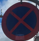

./OURData/padded everything/20261013_110923.jpg


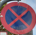

./OURData/padded everything/20261013_111307.jpg
./OURData/padded everything/20261013_111726.jpg


./OURData/padded everything/20261013_111949.jpg


./OURData/padded everything/20261013_112313.jpg


./OURData/padded everything/20261013_112320.jpg


./OURData/padded everything/20261013_112426.jpg


./OURData/padded everything/20261013_112808.jpg


... (3 outputs left out)

./OURData/padded everything/20261013_113119.jpg


./OURData/padded everything/20261013_113232.jpg
./OURData/padded everything/20261013_113241.jpg
./OURData/padded everything/20261013_113316.jpg
./OURData/padded everything/20261013_113324.jpg


./OURData/padded everything/20261013_154038.jpg


./OURData/padded everything/20261013_164442.jpg


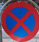

./OURData/padded everything/20261013_164452.jpg


./OURData/padded everything/20261013_164541.jpg
./OURData/padded everything/20261013_164621.jpg
./OURData/padded everything/20261014_151908.jpg


./OURData/padded everything/20261014_151924.jpg


./OURData/padded everything/20261014_151949.jpg


./OURData/padded everything/20261014_152016.jpg


./OURData/padded everything/20261014_152215.jpg


./OURData/padded everything/20261014_163536.jpg
./OURData/padded everything/20261014_163555.jpg
./OURData/padded everything/20261014_184956.jpg
./OURData/padded everything/20261014_185013.jpg


./OURData/padded everything/20261014_185016.jpg


./OURData/padded everything/20261014_185111.jpg


./OURData/padded everything/20261014_185136.jpg


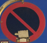

./OURData/padded everything/20261014_185140.jpg


./OURData/padded everything/20261014_185158.jpg
./OURData/padded everything/20261014_185314.jpg


./OURData/padded everything/20261014_185330.jpg


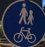

./OURData/padded everything/20261014_185339.jpg
./OURData/padded everything/20261014_185351.jpg
./OURData/padded everything/20261014_185412.jpg
./OURData/padded everything/20261014_185419.jpg


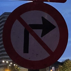

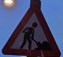

./OURData/padded everything/20261014_185517.jpg
./OURData/padded everything/20261014_185527.jpg
./OURData/padded everything/20261014_185555.jpg


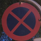

./OURData/padded everything/20261014_185606.jpg


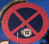

./OURData/padded everything/20261014_185642.jpg
./OURData/padded everything/20261014_185700.jpg


./OURData/padded everything/20261014_185726.jpg


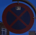

./OURData/padded everything/20261014_185737.jpg


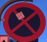

./OURData/padded everything/20261014_185751.jpg
./OURData/padded everything/20261014_185915.jpg
./OURData/padded everything/20261014_190130.jpg


./OURData/padded everything/20261014_190148.jpg
./OURData/padded everything/20261014_190207.jpg


./OURData/padded everything/20261014_190216.jpg


./OURData/padded everything/20261014_190249.jpg


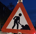

./OURData/padded everything/20261014_190310.jpg


./OURData/padded everything/20261014_190326.jpg


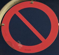

./OURData/padded everything/20261014_190335.jpg


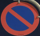

./OURData/padded everything/20261014_190348.jpg


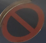

./OURData/padded everything/20261014_190357.jpg


./OURData/padded everything/20261014_190438.jpg


./OURData/padded everything/20261014_190623.jpg
./OURData/padded everything/20261014_190630.jpg
./OURData/padded everything/20261014_190656.jpg


./OURData/padded everything/20261014_190704.jpg


./OURData/padded everything/20261014_190715.jpg


./OURData/padded everything/20261014_190732.jpg
./OURData/padded everything/20261014_190759.jpg
./OURData/padded everything/20261014_190805.jpg
./OURData/padded everything/20261014_190904.jpg
./OURData/padded everything/20261014_190912.jpg


... (3 outputs left out)

./OURData/padded everything/20261014_191004.jpg


./OURData/padded everything/20261014_191128.jpg


./OURData/padded everything/20261014_191139.jpg


./OURData/padded everything/20261014_191240.jpg
./OURData/padded everything/20261014_191307.jpg
./OURData/padded everything/20261014_191325.jpg


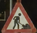

./OURData/padded everything/20261014_191328.jpg


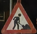

./OURData/padded everything/20261014_191346.jpg
./OURData/padded everything/20261014_191352.jpg
./OURData/padded everything/20261014_191443.jpg
./OURData/padded everything/20261014_191511.jpg
./OURData/padded everything/20261014_191636.jpg
./OURData/padded everything/20261014_191639.jpg
./OURData/padded everything/20261014_191702.jpg
./OURData/padded everything/20261014_191725.jpg
./OURData/padded everything/20261014_191728.jpg
./OURData/padded everything/20261014_192636.jpg
./OURData/padded everything/20261014_192803.jpg


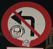

./OURData/padded everything/20261014_195223.jpg


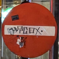

./OURData/padded everything/20261014_195229.jpg


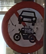

./OURData/padded everything/20261014_195317.jpg
./OURData/padded everything/20261014_204800.jpg
./OURData/padded everything/20261014_205709.jpg


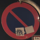

./OURData/padded everything/20261015_121157.jpg
./OURData/padded everything/20261016_171803.jpg


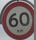

./OURData/padded everything/20261019_180209.jpg


./OURData/padded everything/20261019_180223.jpg
./OURData/padded everything/20261019_180236.jpg
./OURData/padded everything/20261019_180253.jpg


./OURData/padded everything/20261019_180320.jpg


./OURData/padded everything/20261019_180345.jpg
./OURData/padded everything/20261019_180410.jpg
./OURData/padded everything/30 zone.jpeg
./OURData/padded everything/40 km zone og standsning + parkering forbudt skilte.jpeg


./OURData/padded everything/40 zone.jpeg


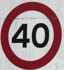

./OURData/padded everything/blind vej med sti til fodgængere og cykel skilt.jpeg
./OURData/padded everything/blindvej med sti.jpeg


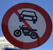

./OURData/padded everything/blindvej.jpeg
./OURData/padded everything/brandskilt med siv foran.jpeg
./OURData/padded everything/bøjet gågade skilt.jpeg
./OURData/padded everything/bøjet skilt af motorkøretøjer og knallert forbudt.jpeg
./OURData/padded everything/cykelparkering forbudt.jpeg
./OURData/padded everything/cykelrute.jpeg
./OURData/padded everything/cykelruter.jpg
./OURData/padded everything/Cykelskilt med klistermærker(1).jpeg
./OURData/padded everything/Cykelskilt med klistermærker.jpeg


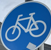

./OURData/padded everything/cykler+1.jpg


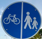

./OURData/padded everything/cykler+2.jpg
./OURData/padded everything/cykler-beskidt.jpg


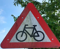

./OURData/padded everything/denne del af vejen skal man holde sig i skilt med klistermærker.jpeg


./OURData/padded everything/dreje til venstre forbudt for lastbiler.jpeg


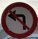

./OURData/padded everything/en_pil.jpg


./OURData/padded everything/fare for bom eller bro kan gå op.jpeg
./OURData/padded everything/fare for og køre i vand skilt.jpeg


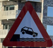

./OURData/padded everything/fareskilt for cykler.jpeg


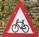

./OURData/padded everything/faretegn og tilhørende tekst.jpeg


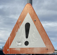

./OURData/padded everything/faretegn.jpeg


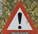

./OURData/padded everything/fodgænger + cykel.jpeg


./OURData/padded everything/fodgænger split op med cykel .jpeg


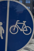

./OURData/padded everything/fodgængere + cykel mod venstre.jpeg


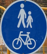

./OURData/padded everything/fodgængere + cykel skilt med klistermærker.jpeg
./OURData/padded everything/fodgængere + cykel.jpeg


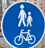

./OURData/padded everything/fodgængere og cykel i begge retninger ophør.jpeg


./OURData/padded everything/fodgængere og cykel i begge retninger skilt.jpeg


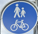

./OURData/padded everything/fodgængere og cykel.jpeg
./OURData/padded everything/fordrejet indkørsel forbudt skilt.jpeg
./OURData/padded everything/graffiti på standsning og parkering forbudt zone.jpeg


./OURData/padded everything/gågade skilt med klistermærke.jpeg
./OURData/padded everything/gågade skilt tildækket med klistermærker.jpeg
./OURData/padded everything/halvt væltet p-zone ophør skilt.jpeg
./OURData/padded everything/Handicapparkering(1).jpeg
./OURData/padded everything/Handicapparkering.jpeg
./OURData/padded everything/hegn foran vejarbejdsskilt.jpeg


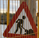

./OURData/padded everything/holde tilbage for modkørende skilt.jpeg


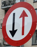

./OURData/padded everything/HORSE.jpg


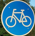

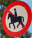

./OURData/padded everything/image010.png
./OURData/padded everything/IMG_2946.jpg
./OURData/padded everything/IMG_2948.jpg
./OURData/padded everything/IMG_2949.jpg


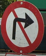

./OURData/padded everything/IMG_2951.jpg


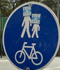

./OURData/padded everything/IMG_2953.jpg


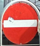

./OURData/padded everything/IMG_2957.jpg
./OURData/padded everything/IMG_2958.jpg


./OURData/padded everything/IMG_2961.jpg
./OURData/padded everything/IMG_2965.jpg


./OURData/padded everything/IMG_2967.jpg


./OURData/padded everything/IMG_2968.jpg


./OURData/padded everything/IMG_2983.jpg
./OURData/padded everything/IMG_2984.jpg


./OURData/padded everything/IMG_2986.jpg


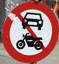

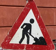

./OURData/padded everything/IMG_2988.jpg


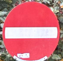

./OURData/padded everything/IMG_2994.jpg


./OURData/padded everything/IMG_3001.jpg


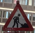

./OURData/padded everything/IMG_3020.jpg


./OURData/padded everything/IMG_3022.jpg


./OURData/padded everything/IMG_3023.jpg
./OURData/padded everything/IMG_3024.jpg


./OURData/padded everything/IMG_3026.jpg


./OURData/padded everything/IMG_3035.jpg


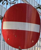

./OURData/padded everything/indkørsel forbudt i begge retninger.jpeg
./OURData/padded everything/indkørsel forbudt skilt med graffiti.jpeg


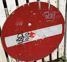

./OURData/padded everything/Indkørsel forbudt skilt.jpeg


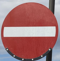

./OURData/padded everything/info om at køre først (et spor) skilt.jpeg
./OURData/padded everything/info om at køre ved kun en bane med klistermærker.jpeg
./OURData/padded everything/klistermærke på cykelruteskilt.jpeg
./OURData/padded everything/klistermærke på p-zone skilt.jpeg
./OURData/padded everything/klistermærker på vejarbejdsskilt.jpeg
./OURData/padded everything/lidt tildækket standsning og parkering forbudt skilt.jpeg
./OURData/padded everything/motorkøretøjer og knallert forbudt + tekst.jpeg


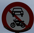

./OURData/padded everything/motorkøretøjer og knallert forbudt med klistermærker.jpeg


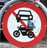

./OURData/padded everything/motorkøretøjer og knallert forbudt.jpeg


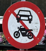

./OURData/padded everything/overdækket faretegn.jpeg
./OURData/padded everything/photo_1_2026-10-21_10-35-58.jpg
./OURData/padded everything/photo_2_2026-10-21_10-35-58.jpg
./OURData/padded everything/photo_3_2026-10-21_10-35-58.jpg
./OURData/padded everything/ryttere + fodgænger + cykel skilt.jpeg


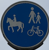

./OURData/padded everything/skilte med klister (1).jpg


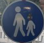

./OURData/padded everything/skilte med klister (2).jpg
./OURData/padded everything/skilte med klister (3).jpg
./OURData/padded everything/skilte med klister .jpg


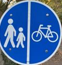

./OURData/padded everything/Skilte med klister.jpg
./OURData/padded everything/skævt p-zone skilt.jpeg
./OURData/padded everything/Slidt og roteret skilt.jpeg


./OURData/padded everything/slidte skilte (faretegn og standsning og parkering forbudt).jpeg


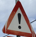

./OURData/padded everything/standsning og parkering forbudt(1).jpeg


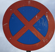

./OURData/padded everything/standsning og parkering forbudt.jpeg


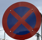

./OURData/padded everything/tildækket med klistermærker (fodgængere forbudt skilt).jpeg


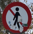

./OURData/padded everything/tildækket mennesker må ikke bevæge sig her skilt.jpeg
./OURData/padded everything/trekant-bøjet.jpg


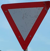

./OURData/padded everything/ubetinget vigepligt.jpeg


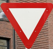

./OURData/padded everything/ubetingetvigepligt skilt.jpeg


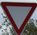

./OURData/padded everything/vejarbejde + indsnævring i den ene bane.jpeg


./OURData/padded everything/vejarbejde + indsnævring.jpeg


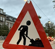

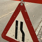

./OURData/padded everything/vejarbejde(1).jpeg
./OURData/padded everything/vejarbejde.jpeg


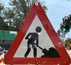

./OURData/padded everything/venstresving forbudt + tekst.jpeg
./OURData/padded everything/vlcsnap-2026-10-21-13h14m03s466.png


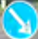

./OURData/padded everything/vlcsnap-2026-10-21-13h19m51s642.png
./OURData/padded everything/vlcsnap-2026-10-21-13h20m09s247.png


./OURData/padded everything/vlcsnap-2026-10-21-13h24m12s284.png


./OURData/padded everything/vlcsnap-2026-10-21-13h24m52s519.png


./OURData/padded everything/vlcsnap-2026-10-21-13h25m44s893.png


./OURData/padded everything/vlcsnap-2026-10-21-13h27m23s365.png


./OURData/padded everything/vlcsnap-2026-10-21-13h27m42s887.png


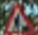

./OURData/padded everything/vlcsnap-2026-10-21-13h28m16s085.png
./OURData/padded everything/vlcsnap-2026-10-21-13h31m26s513.png


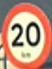

./OURData/padded everything/vlcsnap-2026-10-21-13h34m49s096.png
./OURData/padded everything/vlcsnap-2026-10-21-13h37m10s952.png


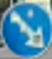

./OURData/padded everything/vlcsnap-2026-10-21-13h38m15s141.png


./OURData/padded everything/vlcsnap-2026-10-21-13h38m44s594.png
./OURData/padded everything/vlcsnap-2026-10-21-13h39m41s927.png
./OURData/padded everything/vlcsnap-2026-10-21-13h40m07s271.png
./OURData/padded everything/vlcsnap-2026-10-21-13h42m37s315.png
./OURData/padded everything/vlcsnap-2026-10-21-13h44m49s989.png


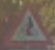

./OURData/padded everything/vlcsnap-2026-10-21-13h45m08s082.png


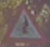

./OURData/padded everything/vlcsnap-2026-10-21-13h46m17s578.png


./OURData/padded everything/væltende blind vej skilt.jpeg
./OURData/padded everything/væltende skilt af påbud om og vente på modsat kørende .jpeg


In [ ]:
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageOps
from os import listdir, makedirs
from os.path import isdir

DatasetPath = "./OURData/padded everything/"
CutPath = "./OURData/cut everything/"
#DatasetPath = "./datasets/GTSDB/images/val/"

imageList = []
filenames = listdir(DatasetPath)
for filename in filenames:
    imageList.append(DatasetPath+filename)
#imageList = ["test.jpg", "Test2.jpg", "test3.png", "test4.png", "test5.png", "test6.png", "test7.png", "test8.png"]
#imageList = [DatasetPath+"test.jpg"]
bmodel = YOLO("./runs/detect/train-25/weights/best.pt")
results = bmodel(imageList)  # return a list of Results objects

def fixImage(path):
    image = Image.open(path)
    image = ImageOps.exif_transpose(image)
    scale = 640 / max(image.width, image.height)
    image = image.resize((int(image.width * scale), int(image.height * scale)))
    #output = Image.new(image.mode, (640, 640), (114, 114, 114))
    #output.paste(image, (int(320 - image.width / 2), int(320 - image.height / 2)))
    return image, scale

# Process results list
for i, result in enumerate(results):
    image, scale = fixImage(imageList[i])
    boxes = result.boxes  # Boxes object for bounding box outputs
    #print(imageList[i])
    for boxID, box in enumerate(boxes):
        x1, y1, x2, y2 = [int(t.item()) for t in box.xyxy[0]]
        x1, y1, x2, y2 = int(x1 * scale), int(y1 * scale), int(x2 * scale), int(y2 * scale)
        boxIm = image.crop((x1, y1, x2, y2))
        #display(boxIm)
        ext = imageList[i].rfind('.')
        ext = imageList[i][ext:]
        boxIm.save(imageList[i].replace(DatasetPath, CutPath)[:-4] +'_'+str(boxID)+ext)
        

    #display(fixImage(imageList[i]))
    #masks = result.masks  # Masks object for segmentation masks outputs
    #keypoints = result.keypoints  # Keypoints object for pose outputs
    #probs = result.probs  # Probs object for classification outputs
    #obb = result.obb  # Oriented boxes object for OBB outputs
    #result.show()  # display to screen
    #result.save(filename="result.jpg")  # save to disk

In [16]:
print(model.device)

cpu
